In [1]:
!pip install -q transformers datasets evaluate accelerate scikit-learn pandas matplotlib seaborn

In [2]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected. Check Colab runtime settings.")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [3]:
from datasets import load_dataset

# Download AG News dataset
dataset = load_dataset("fancyzhx/ag_news")

# Display dataset information
print(dataset)

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})


In [4]:
import pandas as pd

# Convert training and testing data into DataFrames
train_df = pd.DataFrame(dataset["train"])
test_df = pd.DataFrame(dataset["test"])

# Display shapes
print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

# Display first five records
display(train_df.head())

Training shape: (120000, 2)
Testing shape: (7600, 2)


,text,label
0,Wall St. Bears Claw Back Into the Black (Reute...,2
1,Carlyle Looks Toward Commercial Aerospace (Reu...,2
2,Oil and Economy Cloud Stocks' Outlook (Reuters...,2
3,Iraq Halts Oil Exports from Main Southern Pipe...,2
4,"Oil prices soar to all-time record, posing new...",2


category
Business    30000
Sci/Tech    30000
Sports      30000
World       30000
Name: count, dtype: int64


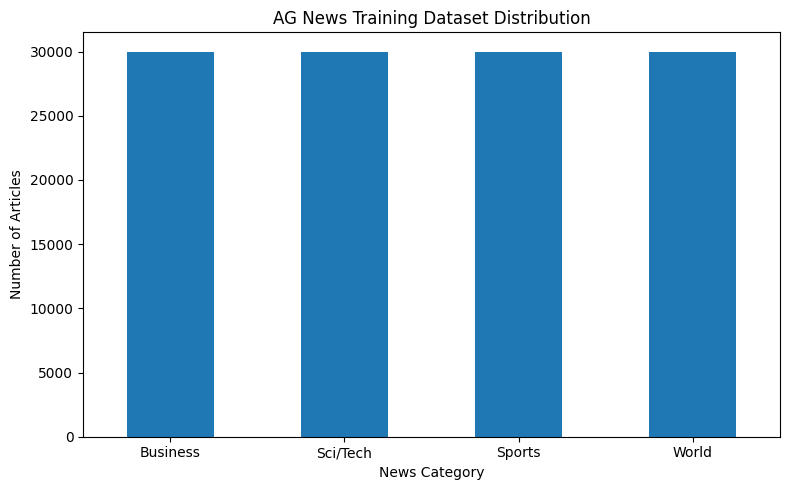

In [5]:
import matplotlib.pyplot as plt

# Class labels
label_names = {
    0: "World",
    1: "Sports",
    2: "Business",
    3: "Sci/Tech"
}

# Convert numeric labels into category names
train_df["category"] = train_df["label"].map(label_names)

# Count samples per category
class_counts = train_df["category"].value_counts()

print(class_counts)

# Plot distribution
plt.figure(figsize=(8, 5))
class_counts.plot(kind="bar")

plt.title("AG News Training Dataset Distribution")
plt.xlabel("News Category")
plt.ylabel("Number of Articles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [6]:
for i in range(5):
    print("=" * 80)
    print("NEWS ARTICLE:", i + 1)
    print("CATEGORY:", label_names[train_df.iloc[i]["label"]])
    print("TITLE + DESCRIPTION:", train_df.iloc[i]["text"])
    print()

NEWS ARTICLE: 1
CATEGORY: Business
TITLE + DESCRIPTION: Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again.

NEWS ARTICLE: 2
CATEGORY: Business
TITLE + DESCRIPTION: Carlyle Looks Toward Commercial Aerospace (Reuters) Reuters - Private investment firm Carlyle Group,\which has a reputation for making well-timed and occasionally\controversial plays in the defense industry, has quietly placed\its bets on another part of the market.

NEWS ARTICLE: 3
CATEGORY: Business
TITLE + DESCRIPTION: Oil and Economy Cloud Stocks' Outlook (Reuters) Reuters - Soaring crude prices plus worries\about the economy and the outlook for earnings are expected to\hang over the stock market next week during the depth of the\summer doldrums.

NEWS ARTICLE: 4
CATEGORY: Business
TITLE + DESCRIPTION: Iraq Halts Oil Exports from Main Southern Pipeline (Reuters) Reuters - Authorities have halted oil export\flows from the main pi

In [7]:
from transformers import AutoTokenizer

MODEL_NAME = "bert-base-uncased"

# Load pretrained BERT tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Tokenizer loaded successfully!")
print("Vocabulary size:", tokenizer.vocab_size)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokenizer loaded successfully!
Vocabulary size: 30522


In [8]:
sample_text = "Apple releases a new iPhone with advanced AI features."

# Tokenize the sentence
tokens = tokenizer.tokenize(sample_text)

# Convert tokens into numerical IDs
input_ids = tokenizer.convert_tokens_to_ids(tokens)

print("Original text:")
print(sample_text)

print("\nTokens:")
print(tokens)

print("\nInput IDs:")
print(input_ids)

Original text:
Apple releases a new iPhone with advanced AI features.

Tokens:
['apple', 'releases', 'a', 'new', 'iphone', 'with', 'advanced', 'ai', 'features', '.']

Input IDs:
[6207, 7085, 1037, 2047, 18059, 2007, 3935, 9932, 2838, 1012]


In [9]:
encoded = tokenizer(
    sample_text,
    add_special_tokens=True
)

print("Tokens:", tokenizer.convert_ids_to_tokens(encoded["input_ids"]))
print("Input IDs:", encoded["input_ids"])
print("Attention Mask:", encoded["attention_mask"])

Tokens: ['[CLS]', 'apple', 'releases', 'a', 'new', 'iphone', 'with', 'advanced', 'ai', 'features', '.', '[SEP]']
Input IDs: [101, 6207, 7085, 1037, 2047, 18059, 2007, 3935, 9932, 2838, 1012, 102]
Attention Mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


In [10]:
MAX_LENGTH = 256

print("Maximum sequence length:", MAX_LENGTH)

Maximum sequence length: 256


In [11]:
def tokenize_function(examples):

    return tokenizer(
        examples["text"],
        padding="max_length",
        truncation=True,
        max_length=MAX_LENGTH
    )


# Tokenize training dataset
tokenized_dataset = dataset.map(
    tokenize_function,
    batched=True
)

print(tokenized_dataset)

Map:   0%|          | 0/120000 [00:00<?, ? examples/s]

Map:   0%|          | 0/7600 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 7600
    })
})


In [12]:
# Remove raw text because BERT receives numerical inputs
tokenized_dataset = tokenized_dataset.remove_columns(["text"])

# Rename label to labels for Hugging Face Trainer
tokenized_dataset = tokenized_dataset.rename_column(
    "label",
    "labels"
)

# Set PyTorch tensor format
# Set PyTorch tensor format
tokenized_dataset.set_format(
    type="torch",
    columns=[
        "input_ids",
        "attention_mask",
        "token_type_ids",
        "labels"
    ]
)

print(tokenized_dataset)
print(tokenized_dataset)

DatasetDict({
    train: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 7600
    })
})
DatasetDict({
    train: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 7600
    })
})


In [13]:
sample = tokenized_dataset["train"][0]

print("Input IDs shape:", sample["input_ids"].shape)
print("Attention Mask shape:", sample["attention_mask"].shape)
print("Label:", sample["labels"])

print("\nFirst 20 Input IDs:")
print(sample["input_ids"][:20])

print("\nFirst 20 Attention Mask values:")
print(sample["attention_mask"][:20])

Input IDs shape: torch.Size([256])
Attention Mask shape: torch.Size([256])
Label: tensor(2)

First 20 Input IDs:
tensor([  101,  2813,  2358,  1012,  6468, 15020,  2067,  2046,  1996,  2304,
         1006, 26665,  1007, 26665,  1011,  2460,  1011, 19041,  1010,  2813])

First 20 Attention Mask values:
tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])


In [14]:
import torch
from transformers import (
    BertForSequenceClassification,
    AutoTokenizer
)

In [15]:
MODEL_NAME = "bert-base-uncased"

NUM_LABELS = 4

id2label = {
    0: "World",
    1: "Sports",
    2: "Business",
    3: "Sci/Tech"
}

label2id = {
    "World": 0,
    "Sports": 1,
    "Business": 2,
    "Sci/Tech": 3
}

In [16]:
import torch
from transformers import BertForSequenceClassification

# Define device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load pretrained BERT classification model
model = BertForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=4,
    id2label=id2label,
    label2id=label2id
)

# Freeze all BERT parameters
for param in model.bert.parameters():
    param.requires_grad = False

# Unfreeze last 3 Transformer layers
for layer in model.bert.encoder.layer[-3:]:
    for param in layer.parameters():
        param.requires_grad = True

# Unfreeze classification head
for param in model.classifier.parameters():
    param.requires_grad = True

# Move model to GPU/CPU
model.to(device)

# Parameter statistics
total_params = sum(p.numel() for p in model.parameters())

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Device:", device)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters: {total_params - trainable_params:,}")
print(f"Trainable percentage: {100 * trainable_params / total_params:.2f}%")

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Device: cuda
Total parameters: 109,485,316
Trainable parameters: 21,266,692
Frozen parameters: 88,218,624
Trainable percentage: 19.42%


In [17]:
# Select one sample
sample = tokenized_dataset["train"][0]

# Add batch dimension
input_ids = sample["input_ids"].unsqueeze(0).to(device)
attention_mask = sample["attention_mask"].unsqueeze(0).to(device)
token_type_ids = sample["token_type_ids"].unsqueeze(0).to(device)

# Evaluation mode
model.eval()

with torch.no_grad():

    outputs = model(
        input_ids=input_ids,
        attention_mask=attention_mask,
        token_type_ids=token_type_ids
    )

print("Logits:", outputs.logits)
print("Logits shape:", outputs.logits.shape)

Logits: tensor([[ 0.0613, -0.3078, -0.1732, -0.1498]], device='cuda:0')
Logits shape: torch.Size([1, 4])


In [18]:
# Reset formatting before splitting
tokenized_dataset.reset_format()

# Split training dataset into train and validation
split_dataset = tokenized_dataset["train"].train_test_split(
    test_size=0.1,
    seed=42,
    stratify_by_column="labels"
)

train_dataset = split_dataset["train"]
val_dataset = split_dataset["test"]

test_dataset = tokenized_dataset["test"]

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))

Training samples: 108000
Validation samples: 12000
Testing samples: 7600


In [19]:
columns = [
    "input_ids",
    "attention_mask",
    "token_type_ids",
    "labels"
]

train_dataset.set_format("torch", columns=columns)
val_dataset.set_format("torch", columns=columns)
test_dataset.set_format("torch", columns=columns)

In [20]:
from transformers import (
    Trainer,
    TrainingArguments,
    DataCollatorWithPadding
)

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

import numpy as np

In [21]:
def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    accuracy = accuracy_score(labels, predictions)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="weighted",
        zero_division=0
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

In [22]:
import transformers
import inspect
from transformers import TrainingArguments

print("Transformers:", transformers.__version__)
print(inspect.signature(TrainingArguments.__init__))

Transformers: 5.22.0
(self, output_dir: str | None = None, per_device_train_batch_size: int = 8, num_train_epochs: float = 3.0, max_steps: int = -1, learning_rate: float = 5e-05, lr_scheduler_type: transformers.trainer_utils.SchedulerType | str = 'linear', lr_scheduler_kwargs: dict | str | None = None, warmup_steps: float = 0, optim: transformers.training_args.OptimizerNames | str = 'adamw_torch_fused', optim_args: str | None = None, weight_decay: float = 0.0, adam_beta1: float = 0.9, adam_beta2: float = 0.999, adam_epsilon: float = 1e-08, optim_target_modules: None | str | list[str] = None, gradient_accumulation_steps: int = 1, average_tokens_across_devices: bool = True, max_grad_norm: float = 1.0, label_smoothing_factor: float = 0.0, bf16: bool = False, fp16: bool = False, bf16_full_eval: bool = False, fp16_full_eval: bool = False, tf32: bool | None = None, gradient_checkpointing: bool = False, gradient_checkpointing_kwargs: dict[str, typing.Any] | str | None = None, torch_compile: b

In [23]:
from transformers import TrainingArguments

training_args = TrainingArguments(

    output_dir="./bert-ag-news-results",

    # Training configuration
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,

    # Optimization
    learning_rate=2e-5,
    weight_decay=0.01,
    optim="adamw_torch",

    # Learning rate warmup
    warmup_steps=2025,

    # Evaluation
    eval_strategy="epoch",

    # Checkpoint saving
    save_strategy="epoch",
    save_total_limit=2,

    # Best model selection
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,

    # GPU acceleration
    fp16=torch.cuda.is_available(),

    # Reproducibility
    seed=42,

    # Logging
    logging_steps=100,
    report_to="none"
)

print("Training arguments configured successfully!")

Training arguments configured successfully!


In [24]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics
)

print("Trainer initialized successfully!")

Trainer initialized successfully!


In [25]:
train_result = trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.211232,0.198445,0.935500,0.935722,0.935500,0.935598
2,0.149100,0.194440,0.939500,0.940370,0.939500,0.939570
3,0.179050,0.185933,0.944250,0.944720,0.944250,0.944343


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

In [26]:
test_results = trainer.evaluate(test_dataset)

print("Test Results:")
for key, value in test_results.items():
    print(f"{key}: {value:.4f}")

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.179050,0.185984,3,0.943816,0.943986,0.943816,0.943873


Test Results:
eval_loss: 0.1860
eval_accuracy: 0.9438
eval_precision: 0.9440
eval_recall: 0.9438
eval_f1: 0.9439


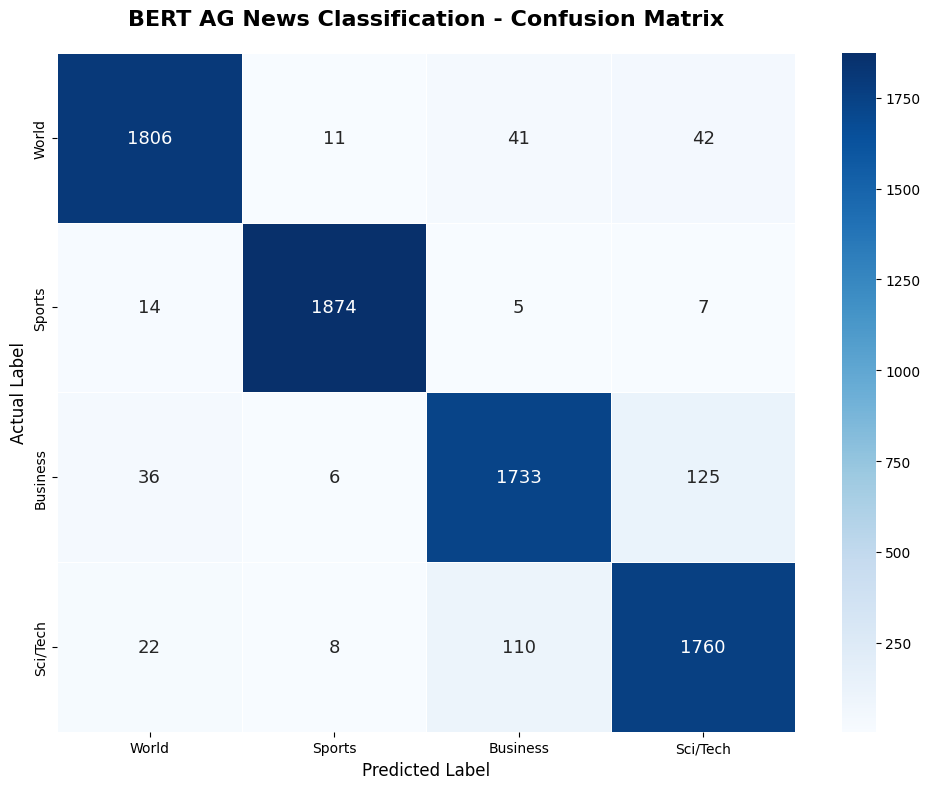

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix
from google.colab import files

# Get test predictions
pred_output = trainer.predict(test_dataset)

y_pred = np.argmax(pred_output.predictions, axis=1)
y_true = pred_output.label_ids

# Class names
class_names = [id2label[i] for i in range(4)]

# Calculate confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Create figure
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    annot_kws={"size": 13},
    linewidths=0.5
)

plt.title(
    "BERT AG News Classification - Confusion Matrix",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("Actual Label", fontsize=12)

plt.tight_layout()

# Save high-resolution figure
filename = "bert_ag_news_confusion_matrix.png"

plt.savefig(
    filename,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Download image
files.download(filename)

In [29]:
import os

MODEL_SAVE_PATH = "./bert-ag-news-model"

# Save fine-tuned model
trainer.save_model(MODEL_SAVE_PATH)

# Save tokenizer
tokenizer.save_pretrained(MODEL_SAVE_PATH)

print("Model and tokenizer saved successfully!")
print("Location:", MODEL_SAVE_PATH)

# Check saved files
print("\nSaved files:")

for file in os.listdir(MODEL_SAVE_PATH):
    print(file)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model and tokenizer saved successfully!
Location: ./bert-ag-news-model

Saved files:
tokenizer_config.json
tokenizer.json
config.json
model.safetensors
training_args.bin


In [30]:
!pip install -q -U huggingface_hub

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.4.0 which is incompatible.


In [31]:
from huggingface_hub import login

login()

In [33]:
from huggingface_hub import create_repo

HF_USERNAME = "sushil9876"
REPO_NAME = "bert-ag-news-classifier"

repo_id = f"{HF_USERNAME}/{REPO_NAME}"

create_repo(
    repo_id=repo_id,
    repo_type="model",
    private=False,
    exist_ok=True
)

print("Repository:", repo_id)
print("URL:", f"https://huggingface.co/{repo_id}")

Repository: sushil9876/bert-ag-news-classifier
URL: https://huggingface.co/sushil9876/bert-ag-news-classifier


In [34]:
model.push_to_hub(
    repo_id,
    commit_message="Upload fine-tuned BERT AG News classifier"
)

tokenizer.push_to_hub(
    repo_id,
    commit_message="Upload tokenizer"
)

print("Upload completed!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...8sazhm3/model.safetensors:   0%|          | 14.2kB /  438MB            

Validating                    :           |   0%            

README.md:   0%|          | 0.00/5.17k [00:00<?, ?B/s]

Upload completed!
